In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("web_traffic_analytics_v2.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (900, 12)


,SessionID,Date,LandingPage,Source,Campaign,DeviceCategory,Region,SessionDurationSec,PageViews,StartedRegistration,Registered,Bounced
0,SESS-500001,2026-02-15,/,Email,none,Mobile,Delhi,243,3,Yes,No,No
1,SESS-500002,2026-06-03,/,Direct,none,Mobile,Karnataka,268,4,No,No,No
2,SESS-500003,2026-04-14,/register,Google Organic,starter,Desktop,Telangana,360,3,Yes,Yes,No
3,SESS-500004,2026-03-31,/register,Email,campus,Desktop,Maharashtra,282,5,Yes,Yes,No
4,SESS-500005,2026-04-24,/programs,Direct,none,Mobile,Tamil Nadu,232,2,No,No,No


In [4]:
print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nTRAFFIC SOURCES")
print(df["Source"].value_counts())

print("\nLANDING PAGES")
print(df["LandingPage"].value_counts())

print("\nREGISTRATION STATUS")
print(df["Registered"].value_counts())

print("\nBOUNCE STATUS")
print(df["Bounced"].value_counts())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   SessionID            900 non-null    str  
 1   Date                 900 non-null    str  
 2   LandingPage          900 non-null    str  
 3   Source               900 non-null    str  
 4   Campaign             900 non-null    str  
 5   DeviceCategory       900 non-null    str  
 6   Region               900 non-null    str  
 7   SessionDurationSec   900 non-null    int64
 8   PageViews            900 non-null    int64
 9   StartedRegistration  900 non-null    str  
 10  Registered           900 non-null    str  
 11  Bounced              900 non-null    str  
dtypes: int64(2), str(10)
memory usage: 84.5 KB

MISSING VALUES
SessionID              0
Date                   0
LandingPage            0
Source                 0
Campaign               0
DeviceCategory         0


In [5]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check unique session IDs
print("Unique Session IDs:", df["SessionID"].nunique())

# Check date conversion
print("\nInvalid Dates:", df["Date"].isna().sum())

# Check numeric values
print("\nSession Duration Summary:")
print(df["SessionDurationSec"].describe())

print("\nPage Views Summary:")
print(df["PageViews"].describe())

# Check Yes/No categories
for col in ["StartedRegistration", "Registered", "Bounced"]:
    print(f"\n{col} values:")
    print(df[col].value_counts())

# Final validation
print("\nFinal Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())

Unique Session IDs: 900

Invalid Dates: 0

Session Duration Summary:
count    900.000000
mean     243.485556
std      140.922421
min        4.000000
25%      140.000000
50%      235.000000
75%      335.000000
max      766.000000
Name: SessionDurationSec, dtype: float64

Page Views Summary:
count    900.000000
mean       3.453333
std        1.928373
min        1.000000
25%        2.000000
50%        3.000000
75%        5.000000
max       11.000000
Name: PageViews, dtype: float64

StartedRegistration values:
StartedRegistration
No     623
Yes    277
Name: count, dtype: int64

Registered values:
Registered
No     734
Yes    166
Name: count, dtype: int64

Bounced values:
Bounced
No     856
Yes     44
Name: count, dtype: int64

Final Dataset Shape: (900, 12)
Duplicate Rows: 0
Missing Values: 0


In [6]:
# Total sessions
total_sessions = len(df)

# Bounce rate
bounced_sessions = (df["Bounced"] == "Yes").sum()
bounce_rate = (bounced_sessions / total_sessions) * 100

# Average session duration
avg_duration = df["SessionDurationSec"].mean()
avg_duration_minutes = avg_duration / 60

# Average pageviews
avg_pageviews = df["PageViews"].mean()

# Registration metrics
started = (df["StartedRegistration"] == "Yes").sum()
registered = (df["Registered"] == "Yes").sum()

registration_rate = (registered / total_sessions) * 100
registration_start_rate = (started / total_sessions) * 100
completion_rate = (registered / started) * 100

print("WEBSITE TRAFFIC KEY METRICS")
print("--------------------------------")
print("Total Sessions:", total_sessions)
print("Bounced Sessions:", bounced_sessions)
print("Bounce Rate:", round(bounce_rate, 2), "%")
print("Average Session Duration:", round(avg_duration, 2), "seconds")
print("Average Session Duration:", round(avg_duration_minutes, 2), "minutes")
print("Average Pageviews:", round(avg_pageviews, 2))
print("Registration Starts:", started)
print("Completed Registrations:", registered)
print("Registration Conversion Rate:", round(registration_rate, 2), "%")
print("Registration Start Rate:", round(registration_start_rate, 2), "%")
print("Registration Completion Rate:", round(completion_rate, 2), "%")

WEBSITE TRAFFIC KEY METRICS
--------------------------------
Total Sessions: 900
Bounced Sessions: 44
Bounce Rate: 4.89 %
Average Session Duration: 243.49 seconds
Average Session Duration: 4.06 minutes
Average Pageviews: 3.45
Registration Starts: 277
Completed Registrations: 166
Registration Conversion Rate: 18.44 %
Registration Start Rate: 30.78 %
Registration Completion Rate: 59.93 %


In [7]:
source_analysis = df.groupby("Source").agg(
    Total_Sessions=("SessionID", "count"),
    Bounced_Sessions=("Bounced", lambda x: (x == "Yes").sum()),
    Registration_Started=("StartedRegistration", lambda x: (x == "Yes").sum()),
    Completed_Registrations=("Registered", lambda x: (x == "Yes").sum()),
    Average_Duration=("SessionDurationSec", "mean"),
    Average_PageViews=("PageViews", "mean")
)

source_analysis["Bounce_Rate"] = (
    source_analysis["Bounced_Sessions"] /
    source_analysis["Total_Sessions"] * 100
)

source_analysis["Conversion_Rate"] = (
    source_analysis["Completed_Registrations"] /
    source_analysis["Total_Sessions"] * 100
)

source_analysis["Start_Rate"] = (
    source_analysis["Registration_Started"] /
    source_analysis["Total_Sessions"] * 100
)

source_analysis = source_analysis.round(2)

display(source_analysis.sort_values(
    by="Conversion_Rate", ascending=False
))

,Total_Sessions,Bounced_Sessions,Registration_Started,Completed_Registrations,Average_Duration,Average_PageViews,Bounce_Rate,Conversion_Rate,Start_Rate
Source,,,,,,,,,
Instagram,93,4,37,22,263.78,3.74,4.30,23.66,39.78
Email,127,6,41,30,243.27,3.51,4.72,23.62,32.28
Referral,85,6,27,16,222.36,3.29,7.06,18.82,31.76
Direct,207,12,62,36,228.16,3.32,5.80,17.39,29.95
LinkedIn,123,8,33,21,238.72,3.38,6.50,17.07,26.83
Google Organic,265,8,77,41,257.42,3.51,3.02,15.47,29.06


In [8]:
page_analysis = df.groupby("LandingPage").agg(
    Total_Sessions=("SessionID", "count"),
    Registration_Started=("StartedRegistration",
                          lambda x: (x == "Yes").sum()),
    Completed_Registrations=("Registered",
                             lambda x: (x == "Yes").sum()),
    Bounced_Sessions=("Bounced",
                      lambda x: (x == "Yes").sum())
)

page_analysis["Start_Rate"] = (
    page_analysis["Registration_Started"] /
    page_analysis["Total_Sessions"] * 100
)

page_analysis["Conversion_Rate"] = (
    page_analysis["Completed_Registrations"] /
    page_analysis["Total_Sessions"] * 100
)

page_analysis["Bounce_Rate"] = (
    page_analysis["Bounced_Sessions"] /
    page_analysis["Total_Sessions"] * 100
)

page_analysis["Registration_Dropoffs"] = (
    page_analysis["Registration_Started"] -
    page_analysis["Completed_Registrations"]
)

page_analysis = page_analysis.round(2)

display(page_analysis.sort_values(
    by="Registration_Dropoffs",
    ascending=False
))

,Total_Sessions,Registration_Started,Completed_Registrations,Bounced_Sessions,Start_Rate,Conversion_Rate,Bounce_Rate,Registration_Dropoffs
LandingPage,,,,,,,,
/,161,45,21,12,27.95,13.04,7.45,24
/programs,161,49,29,5,30.43,18.01,3.11,20
/verify,139,48,28,11,34.53,20.14,7.91,20
/faq,144,44,26,5,30.56,18.06,3.47,18
/login,144,49,33,3,34.03,22.92,2.08,16
/register,151,42,29,8,27.81,19.21,5.30,13


In [9]:
device_analysis = df.groupby("DeviceCategory").agg(
    Total_Sessions=("SessionID", "count"),
    Average_Duration=("SessionDurationSec", "mean"),
    Average_PageViews=("PageViews", "mean"),
    Registration_Started=("StartedRegistration",
                          lambda x: (x == "Yes").sum()),
    Completed_Registrations=("Registered",
                             lambda x: (x == "Yes").sum()),
    Bounced_Sessions=("Bounced",
                      lambda x: (x == "Yes").sum())
)

device_analysis["Conversion_Rate"] = (
    device_analysis["Completed_Registrations"] /
    device_analysis["Total_Sessions"] * 100
)

device_analysis["Bounce_Rate"] = (
    device_analysis["Bounced_Sessions"] /
    device_analysis["Total_Sessions"] * 100
)

device_analysis = device_analysis.round(2)

display(device_analysis)

,Total_Sessions,Average_Duration,Average_PageViews,Registration_Started,Completed_Registrations,Bounced_Sessions,Conversion_Rate,Bounce_Rate
DeviceCategory,,,,,,,,
Desktop,261,247.59,3.49,89,57,12,21.84,4.60
Mobile,593,242.26,3.45,178,104,30,17.54,5.06
Tablet,46,236.04,3.28,10,5,2,10.87,4.35


In [10]:
funnel_data = pd.DataFrame({
    "Stage": [
        "Total Sessions",
        "Registration Started",
        "Registration Completed"
    ],
    "Users": [
        len(df),
        (df["StartedRegistration"] == "Yes").sum(),
        (df["Registered"] == "Yes").sum()
    ]
})

funnel_data["Dropoffs"] = (
    funnel_data["Users"].shift(0) -
    funnel_data["Users"].shift(-1)
)

funnel_data["Conversion_From_Previous"] = [
    100,
    round(277 / 900 * 100, 2),
    round(166 / 277 * 100, 2)
]

display(funnel_data)

,Stage,Users,Dropoffs,Conversion_From_Previous
0,Total Sessions,900,623.0,100.00
1,Registration Started,277,111.0,30.78
2,Registration Completed,166,NaN,59.93


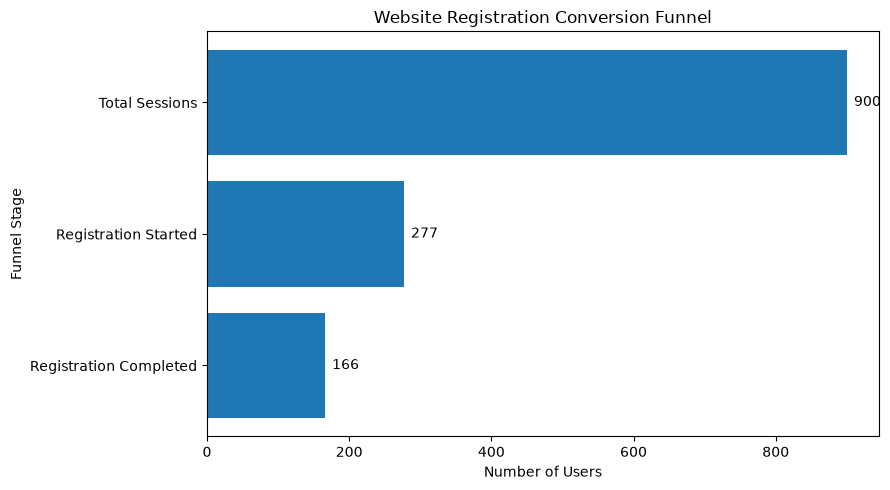

In [11]:
stages = [
    "Total Sessions",
    "Registration Started",
    "Registration Completed"
]

users = [900, 277, 166]

plt.figure(figsize=(9, 5))

bars = plt.barh(stages, users)

plt.title("Website Registration Conversion Funnel")
plt.xlabel("Number of Users")
plt.ylabel("Funnel Stage")
plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 10,
        bar.get_y() + bar.get_height()/2,
        str(int(width)),
        va="center"
    )

plt.tight_layout()
plt.show()

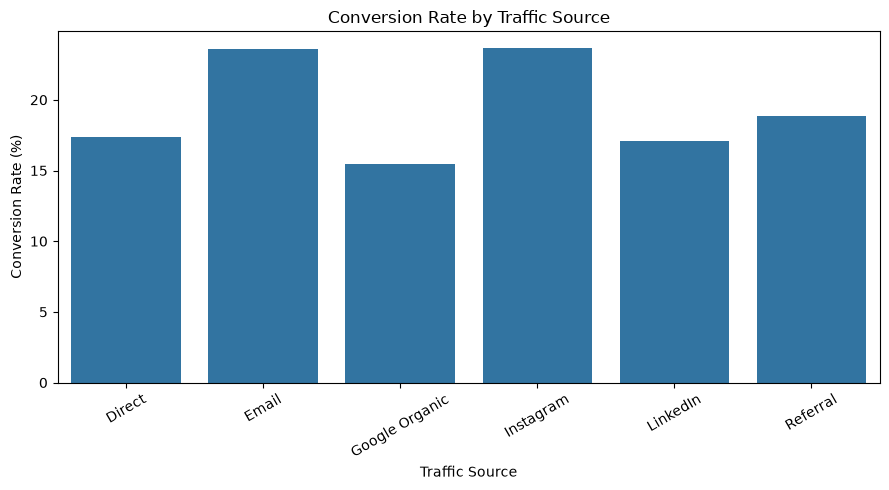

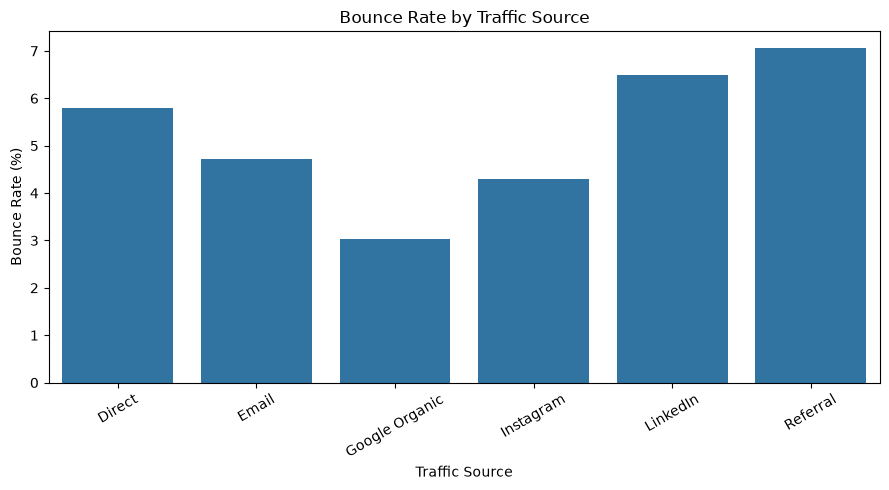

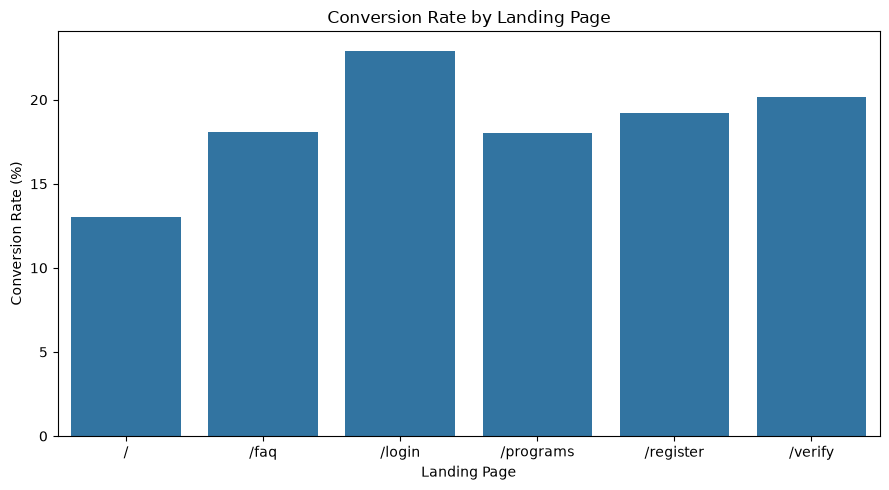

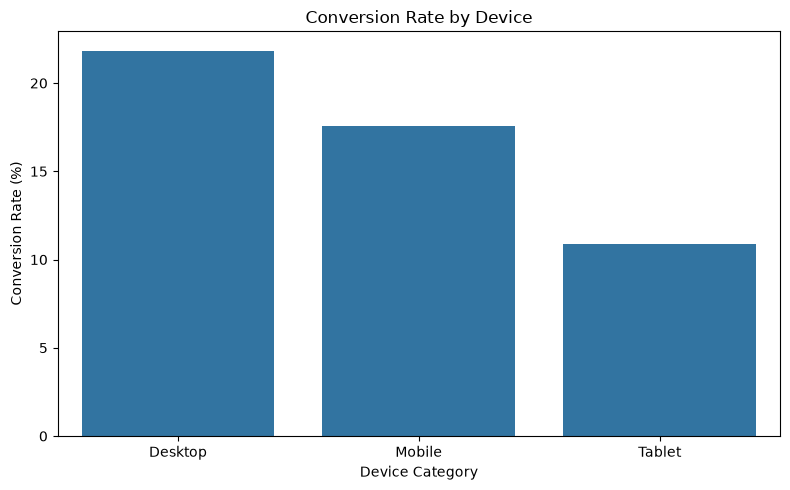

All 4 charts saved successfully!


In [12]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("output/charts", exist_ok=True)

# 1. Traffic Source Conversion Rate
plt.figure(figsize=(9, 5))
sns.barplot(
    x=source_analysis.index,
    y=source_analysis["Conversion_Rate"]
)
plt.title("Conversion Rate by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("output/charts/source_conversion.png", dpi=300)
plt.show()


# 2. Traffic Source Bounce Rate
plt.figure(figsize=(9, 5))
sns.barplot(
    x=source_analysis.index,
    y=source_analysis["Bounce_Rate"]
)
plt.title("Bounce Rate by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Bounce Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("output/charts/source_bounce.png", dpi=300)
plt.show()


# 3. Landing Page Conversion Rate
plt.figure(figsize=(9, 5))
sns.barplot(
    x=page_analysis.index,
    y=page_analysis["Conversion_Rate"]
)
plt.title("Conversion Rate by Landing Page")
plt.xlabel("Landing Page")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.savefig("output/charts/landing_page_conversion.png", dpi=300)
plt.show()


# 4. Device Conversion Rate
plt.figure(figsize=(8, 5))
sns.barplot(
    x=device_analysis.index,
    y=device_analysis["Conversion_Rate"]
)
plt.title("Conversion Rate by Device")
plt.xlabel("Device Category")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.savefig("output/charts/device_conversion.png", dpi=300)
plt.show()

print("All 4 charts saved successfully!")

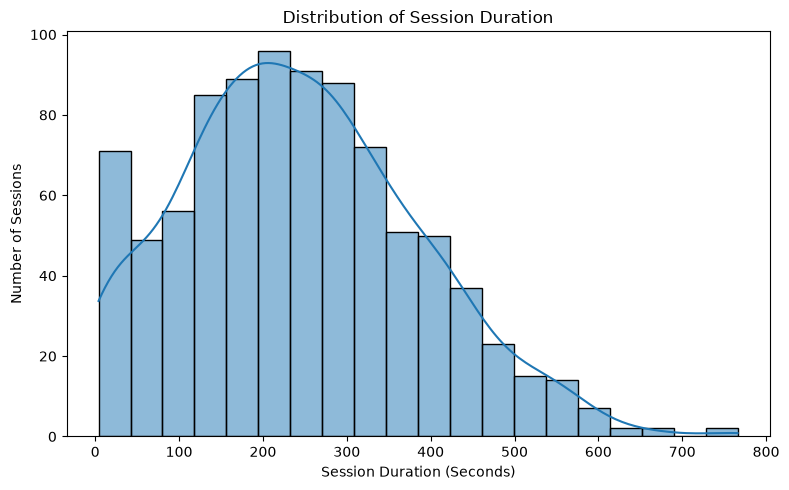

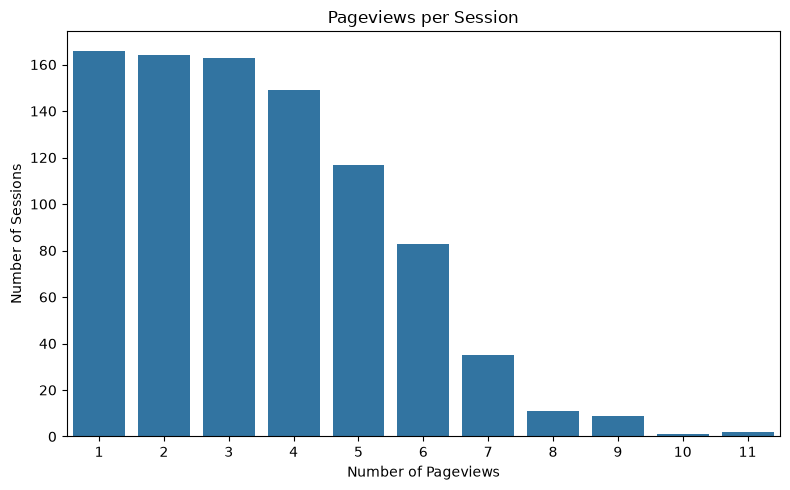

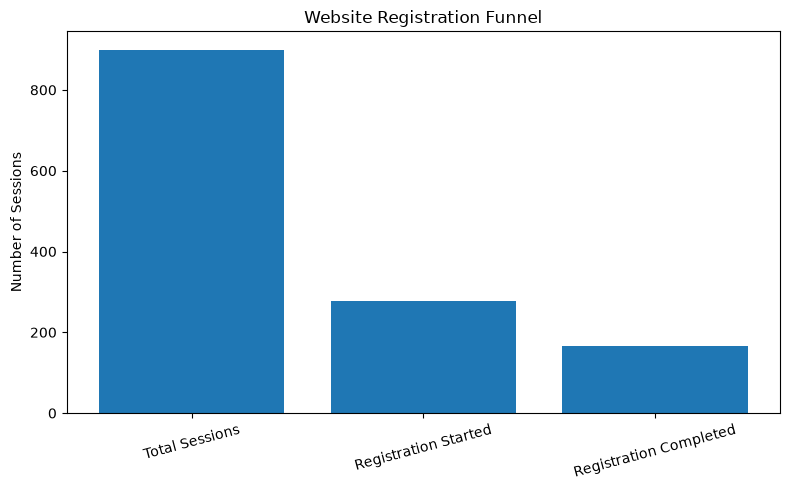

Engagement and funnel charts saved successfully!


In [13]:
# 5. Session Duration Distribution
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="SessionDurationSec",
    bins=20,
    kde=True
)
plt.title("Distribution of Session Duration")
plt.xlabel("Session Duration (Seconds)")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.savefig("output/charts/session_duration_distribution.png", dpi=300)
plt.show()


# 6. Pageviews Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="PageViews"
)
plt.title("Pageviews per Session")
plt.xlabel("Number of Pageviews")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.savefig("output/charts/pageviews_distribution.png", dpi=300)
plt.show()


# 7. Registration Funnel
plt.figure(figsize=(8, 5))
plt.bar(
    ["Total Sessions", "Registration Started", "Registration Completed"],
    [900, 277, 166]
)
plt.title("Website Registration Funnel")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("output/charts/conversion_funnel.png", dpi=300)
plt.show()

print("Engagement and funnel charts saved successfully!")

In [14]:
# Create output folder if it doesn't exist
import os
os.makedirs("output", exist_ok=True)

# Save analysis tables
source_analysis.to_csv("output/source_analysis.csv")
page_analysis.to_csv("output/landing_page_analysis.csv")
device_analysis.to_csv("output/device_analysis.csv")
funnel_data.to_csv("output/conversion_funnel.csv", index=False)

print("All analysis tables saved successfully!")

print("\nSaved files:")
print("1. source_analysis.csv")
print("2. landing_page_analysis.csv")
print("3. device_analysis.csv")
print("4. conversion_funnel.csv")

All analysis tables saved successfully!

Saved files:
1. source_analysis.csv
2. landing_page_analysis.csv
3. device_analysis.csv
4. conversion_funnel.csv


In [15]:
import os

print("OUTPUT FOLDER FILES:\n")

for root, dirs, files in os.walk("output"):
    for file in files:
        print(os.path.join(root, file))

OUTPUT FOLDER FILES:

output\conversion_funnel.csv
output\device_analysis.csv
output\landing_page_analysis.csv
output\source_analysis.csv
output\charts\conversion_funnel.png
output\charts\device_conversion.png
output\charts\landing_page_conversion.png
output\charts\pageviews_distribution.png
output\charts\session_duration_distribution.png
output\charts\source_bounce.png
output\charts\source_conversion.png


In [16]:

%pip install reportlab

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\SHREE VATHY\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [17]:

import os
import pandas as pd

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    Image, PageBreak
)

# Create output folder
os.makedirs("output", exist_ok=True)

pdf_path = "output/web_traffic_analytics_dashboard.pdf"

# PDF setup
doc = SimpleDocTemplate(
    pdf_path,
    pagesize=landscape(A4),
    rightMargin=35,
    leftMargin=35,
    topMargin=35,
    bottomMargin=35
)

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    "CustomTitle",
    parent=styles["Title"],
    fontSize=24,
    textColor=colors.HexColor("#17365D"),
    alignment=TA_CENTER,
    spaceAfter=12
)

heading_style = ParagraphStyle(
    "CustomHeading",
    parent=styles["Heading2"],
    fontSize=15,
    textColor=colors.HexColor("#1F4E79"),
    spaceBefore=10,
    spaceAfter=8
)

normal_style = styles["BodyText"]

story = []

# Calculate key metrics
total_sessions = len(df)
bounced_sessions = (df["Bounced"] == "Yes").sum()
bounce_rate = bounced_sessions / total_sessions * 100

avg_duration = df["SessionDurationSec"].mean()
avg_pageviews = df["PageViews"].mean()

registration_starts = (df["StartedRegistration"] == "Yes").sum()
completed_registrations = (df["Registered"] == "Yes").sum()

overall_conversion = completed_registrations / total_sessions * 100
completion_rate = completed_registrations / registration_starts * 100

# Helper function for tables
def create_report_table(data, widths):
    table = Table(data, colWidths=widths, repeatRows=1)

    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (-1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#EAF2F8")]),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("ALIGN", (1, 1), (-1, -1), "CENTER"),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6)
    ]))

    return table

# ---------------- PAGE 1: OVERVIEW ----------------

story.append(Paragraph("WEB TRAFFIC ANALYTICS REPORT", title_style))
story.append(Paragraph(
    "Website Traffic, Engagement and Registration Conversion Analysis",
    ParagraphStyle(
        "Subtitle",
        parent=normal_style,
        alignment=TA_CENTER,
        fontSize=11
    )
))
story.append(Spacer(1, 20))

story.append(Paragraph("1. Project Overview", heading_style))
story.append(Paragraph(
    "This project analyzes website session data to understand traffic "
    "sources, visitor engagement, landing-page performance, device-based "
    "behavior and registration conversion. The objective is to identify "
    "performance gaps and provide data-driven improvement recommendations.",
    normal_style
))

story.append(Spacer(1, 12))
story.append(Paragraph("2. Key Performance Indicators", heading_style))

kpi_data = [
    ["Metric", "Result", "Metric", "Result"],
    ["Total Sessions", str(total_sessions),
     "Bounce Rate", f"{bounce_rate:.2f}%"],
    ["Average Session Duration", f"{avg_duration:.2f} sec",
     "Average Pageviews", f"{avg_pageviews:.2f}"],
    ["Registration Starts", str(registration_starts),
     "Completed Registrations", str(completed_registrations)],
    ["Overall Conversion Rate", f"{overall_conversion:.2f}%",
     "Registration Completion Rate", f"{completion_rate:.2f}%"]
]

story.append(create_report_table(
    kpi_data, [180, 150, 180, 150]
))

story.append(Spacer(1, 12))
story.append(Paragraph("3. Dataset Information", heading_style))
story.append(Paragraph(
    f"The dataset contains {len(df)} website sessions and "
    f"{len(df.columns)} columns. It includes session dates, landing pages, "
    "traffic sources, campaigns, device categories, regions, session "
    "duration, pageviews, registration activity and bounce status.",
    normal_style
))

story.append(PageBreak())

# ---------------- PAGE 2: SOURCE ANALYSIS ----------------

story.append(Paragraph("4. Traffic Source Analysis", heading_style))

source_df = source_analysis.reset_index()

source_columns = [
    "Source", "Total_Sessions", "Bounce_Rate",
    "Conversion_Rate", "Average_PageViews"
]

source_data = [["Source", "Sessions", "Bounce Rate",
                "Conversion Rate", "Avg Pageviews"]]

for _, row in source_df.iterrows():
    source_data.append([
        str(row["Source"]),
        str(int(row["Total_Sessions"])),
        f'{row["Bounce_Rate"]:.2f}%',
        f'{row["Conversion_Rate"]:.2f}%',
        f'{row["Average_PageViews"]:.2f}'
    ])

story.append(create_report_table(
    source_data, [160, 110, 130, 150, 130]
))

story.append(Spacer(1, 12))
story.append(Paragraph("5. Landing Page Analysis", heading_style))

page_df = page_analysis.reset_index()

page_data = [[
    "Landing Page", "Sessions", "Starts",
    "Completed", "Drop-offs", "Conversion Rate"
]]

for _, row in page_df.iterrows():
    page_data.append([
        str(row["LandingPage"]),
        str(int(row["Total_Sessions"])),
        str(int(row["Registration_Started"])),
        str(int(row["Completed_Registrations"])),
        str(int(row["Registration_Dropoffs"])),
        f'{row["Conversion_Rate"]:.2f}%'
    ])

story.append(create_report_table(
    page_data, [130, 100, 100, 110, 100, 150]
))

story.append(Spacer(1, 10))
story.append(Paragraph(
    "Note: Landing-page results represent session outcomes grouped by "
    "the recorded landing page. The dataset does not contain page-by-page "
    "navigation or exit-page tracking.",
    normal_style
))

story.append(PageBreak())

# ---------------- PAGE 3: DEVICE & FUNNEL ----------------

story.append(Paragraph("6. Device Category Analysis", heading_style))

device_df = device_analysis.reset_index()

device_data = [[
    "Device", "Sessions", "Avg Duration (sec)",
    "Avg Pageviews", "Conversion Rate", "Bounce Rate"
]]

for _, row in device_df.iterrows():
    device_data.append([
        str(row["DeviceCategory"]),
        str(int(row["Total_Sessions"])),
        f'{row["Average_Duration"]:.2f}',
        f'{row["Average_PageViews"]:.2f}',
        f'{row["Conversion_Rate"]:.2f}%',
        f'{row["Bounce_Rate"]:.2f}%'
    ])

story.append(create_report_table(
    device_data, [110, 100, 150, 120, 140, 120]
))

story.append(Spacer(1, 15))
story.append(Paragraph("7. Registration Funnel", heading_style))

funnel_table = [
    ["Funnel Stage", "Sessions", "Conversion from Previous Stage"],
    ["Total Sessions", "900", "100.00%"],
    ["Registration Started", "277", "30.78%"],
    ["Registration Completed", "166", "59.93%"]
]

story.append(create_report_table(
    funnel_table, [230, 150, 230]
))

story.append(Spacer(1, 12))
story.append(Paragraph(
    "A total of 623 sessions did not start registration. Another 111 "
    "sessions started registration but did not complete it. Overall, "
    "166 out of 900 sessions resulted in completed registrations.",
    normal_style
))

story.append(PageBreak())

# ---------------- PAGES 4 & 5: CHARTS ----------------

chart_files = [
    ("Traffic Source Conversion Rate", "source_conversion.png"),
    ("Traffic Source Bounce Rate", "source_bounce.png"),
    ("Landing Page Conversion Rate", "landing_page_conversion.png"),
    ("Device Conversion Rate", "device_conversion.png"),
    ("Session Duration Distribution", "session_duration_distribution.png"),
    ("Pageviews Distribution", "pageviews_distribution.png"),
    ("Registration Conversion Funnel", "conversion_funnel.png")
]

for index, (chart_title, filename) in enumerate(chart_files):
    chart_path = os.path.join("output", "charts", filename)

    if os.path.exists(chart_path):
        story.append(Paragraph(chart_title, heading_style))
        chart = Image(chart_path, width=430, height=260)
        story.append(chart)
        story.append(Spacer(1, 10))

    if index in [2, 4]:
        story.append(PageBreak())

story.append(PageBreak())

# ---------------- FINAL PAGE: FINDINGS ----------------

story.append(Paragraph("8. Key Findings", heading_style))

findings = [
    f"Instagram recorded the highest source conversion rate at 23.66%.",
    f"Email recorded a conversion rate of 23.62%.",
    f"Google Organic generated the highest traffic with 265 sessions, "
    f"but its conversion rate was 15.47%.",
    f"Referral traffic recorded the highest source bounce rate at 7.06%.",
    f"The homepage (/) had the highest registration drop-off count at 24.",
    f"Desktop users recorded the highest device conversion rate at 21.84%.",
    f"Mobile devices generated the highest traffic with 593 sessions.",
    f"Tablet users had the lowest device conversion rate at 10.87%."
]

for finding in findings:
    story.append(Paragraph("• " + finding, normal_style))
    story.append(Spacer(1, 5))

story.append(Paragraph("9. Recommendations", heading_style))

recommendations = [
    "Study Instagram and Email campaigns to understand which factors "
    "contribute to their stronger conversion rates.",
    "Review Google Organic landing-page relevance and improve calls to action.",
    "Investigate Referral traffic quality and landing-page experience.",
    "Review homepage content and registration prompts to reduce drop-offs.",
    "Test and improve the mobile registration experience.",
    "Investigate tablet usability and responsive design.",
    "Track page-level navigation and exit events in future analytics "
    "to identify exact drop-off pages."
]

for recommendation in recommendations:
    story.append(Paragraph("• " + recommendation, normal_style))
    story.append(Spacer(1, 5))

story.append(Paragraph("10. Data Limitations", heading_style))
story.append(Paragraph(
    "The dataset contains no explicit Ads traffic category. The available "
    "sources are Google Organic, Direct, Email, LinkedIn, Instagram and "
    "Referral. Exact exit pages and page-by-page navigation are not "
    "recorded, so specific exit-page claims cannot be established. "
    "The findings describe the supplied dataset and do not prove causation.",
    normal_style
))

story.append(Spacer(1, 18))
story.append(Paragraph(
    "Prepared by: SHREE VATHY S",
    ParagraphStyle(
        "Author",
        parent=normal_style,
        fontName="Helvetica-Bold",
        fontSize=12,
        textColor=colors.HexColor("#17365D")
    )
))
story.append(Paragraph(
    "Workora – Data Analytics Virtual Internship",
    normal_style
))

# Generate PDF
doc.build(story)

print("PDF generated successfully!")
print("File location:", os.path.abspath(pdf_path))


PDF generated successfully!
File location: C:\Users\SHREE VATHY\OneDrive\Desktop\workora\web_traffic_analytics\output\web_traffic_analytics_dashboard.pdf
